# Fundación YPF - Data Science
# Pre-entrega 4 - Grupo 7: Modelo de Aprendizaje No Supervisado

**Consigna:** aplicación de un algoritmo de Aprendizaje No Supervisado (clustering) al dataset del proyecto partiendo de la exploración y limpieza de la Pre-entrega 2.

## Dataset

`pozos_fractura_limpio.csv`: el dataset de fracturas de pozos de hidrocarburos que limpiamos en la Pre-entrega 2 (`data/processed/pozos_fractura_limpio.csv`).

## Parte 0. El problema y la pregunta

En la **Pre-entrega 3** entrenamos un modelo supervisado para predecir cuántas toneladas de arena iba a necesitar un pozo (`arena_total_tn`). Al analizar los resultados y los errores, vimos que en la base conviven pozos de escalas muy distintas: desde fracturas chicas de pocas toneladas hasta fracturas masivas en Vaca Muerta que requieren miles de toneladas y cientos de camiones.

En el aprendizaje no supervisado no buscamos predecir una columna objetivo $y$, sino encontrar estructura y grupos naturales dentro de los datos. Por eso nos planteamos una pregunta directa y fácil de responder para el proyecto:

> **Pregunta:** *Si agrupamos los pozos únicamente por sus medidas operativas de fractura (sin mirar las etiquetas de formación ni de tipo de reservorio), ¿aparecen perfiles claros de pozos (por ejemplo: chicos, medianos y grandes) que nos sirvan para organizar la logística de arena y equipos?*

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

COLORES = {1: '#2E86C1', 2: '#28B463', 3: '#E67E22'}

In [ ]:
def cargar(nombre='pozos_fractura_limpio.csv'):
    '''Busca el archivo en las carpetas del proyecto o en /content/ (Colab).'''
    rutas = [
        os.path.join('..', '..', 'data', 'processed', nombre),
        os.path.join('data', 'processed', nombre),
        os.path.join('/content', nombre),
        nombre,
    ]
    for r in rutas:
        if os.path.exists(r):
            return pd.read_csv(r)
    raise FileNotFoundError(f'No se encontró {nombre}')

df = cargar('pozos_fractura_limpio.csv')
print('Dimensiones del dataset:', df.shape)
df.head()

Dimensiones del dataset: (4888, 36)


,_id,id_base_fractura_adjiv,idpozo,sigla,cuenca,areapermisoconcesion,yacimiento,formacion_productiva,tipo_reservorio,subtipo_reservorio,longitud_rama_horizontal_m,cantidad_fracturas,tipo_terminacion,arena_bombeada_nacional_tn,arena_bombeada_importada_tn,agua_inyectada_m3,co2_inyectado_m3,presion_maxima_psi,potencia_equipos_fractura_hp,fecha_inicio_fractura,fecha_fin_fractura,fecha_data,anio_if,mes_if,anio_ff,mes_ff,empresa_informante,arena_total_tn,agua_no_informada,sin_insumos_informados,presion_imputada,potencia_imputada,fecha_corregida,duracion_fractura_dias,es_horizontal,rama_imputada
0,1,30,159910,APS.Nq.ADC.xp-1033,neuquina,agua del cajon,agua del cajon,los molles,no convencional,shale,0.0,3,punzado,0.000,0.000,2718.20,0.0,10190.0,10897.0,2019-04-20,2019-04-30,2019-06-14 17:13:03,2019,4,2019,4,capex s.a.,0.000,False,False,False,False,False,10,False,False
1,2,31,159910,APS.Nq.ADC.xp-1033,neuquina,agua del cajon,agua del cajon,los molles,no convencional,shale,0.0,1,punzado,0.000,0.000,600.00,0.0,9250.0,10251.0,2018-11-02,2018-11-03,2019-06-14 17:14:19,2018,11,2018,11,capex s.a.,0.000,False,False,False,False,False,1,False,False
2,3,37,159219,YPF.Nq.AdlA-1001(h),neuquina,aguada de la arena,aguada de la arena,vaca muerta,no convencional,shale,1437.3,18,tapón disparo,3761.370,536.850,25768.30,0.0,15000.0,32000.0,2017-11-19,2017-12-14,2019-06-27 13:46:21,2017,11,2017,12,ypf s.a.,4298.220,False,False,False,False,False,25,True,False
3,4,38,159220,YPF.Nq.AdlA-1002(h),neuquina,aguada de la arena,aguada de la arena,vaca muerta,no convencional,shale,1518.3,19,tapón disparo,3903.705,558.225,27398.37,0.0,11348.0,32000.0,2017-11-21,2017-12-15,2019-06-27 13:46:21,2017,11,2017,12,ypf s.a.,4461.930,False,False,False,False,False,24,True,False
4,5,39,159221,YPF.Nq.AdlA-1003(h),neuquina,aguada de la arena,aguada de la arena,vaca muerta,no convencional,shale,1482.3,19,tapón disparo,3949.020,569.925,27157.60,0.0,11076.0,32000.0,2017-11-18,2017-12-15,2019-06-27 13:46:21,2017,11,2017,12,ypf s.a.,4518.945,False,False,False,False,False,27,True,False


## Parte 1. Selección de variables y preparación de los datos

En clustering el modelo calcula distancias usando todas las columnas que pongamos en `X`. Por eso tomamos tres decisiones simples sobre qué columnas incluir y cuáles dejar afuera:

1. **Variables que entran al modelo (`X`):** elegimos las **6 variables numéricas** que describen el tamaño del trabajo y la exigencia de los equipos:
   - `longitud_rama_horizontal_m` (largo de la rama horizontal en metros; vale 0 en pozos verticales)
   - `cantidad_fracturas` (cantidad de etapas de fractura)
   - `arena_total_tn` (toneladas totales de arena bombeada)
   - `agua_inyectada_m3` (metros cúbicos de agua inyectada)
   - `presion_maxima_psi` (presión máxima en psi)
   - `potencia_equipos_fractura_hp` (potencia de las bombas en HP)
2. **Variables que dejamos afuera para no repetir información:** no incluimos `arena_bombeada_nacional_tn` ni `arena_bombeada_importada_tn` (porque su suma ya es `arena_total_tn`). Tampoco usamos identificadores (`idpozo`, `sigla`).
3. **Variables que guardamos como "pista externa":** dejamos afuera `subtipo_reservorio` (`shale`, `tight`, `no corresponde` [convencional]) y `cuenca` (`neuquina`, `golfo san jorge`, `austral`). El algoritmo no las va a ver al armar los grupos, pero las vamos a usar al final (Parte 6) para chequear si los grupos encontrados tienen sentido geológico y geográfico. No usamos `tipo_reservorio` porque repite la información de `subtipo_reservorio` (`convencional` equivale a `no corresponde`, y `no convencional` agrupa `shale` + `tight`).

**Unidad de análisis:** cada fila del dataset es un **registro de fractura**, no un pozo único: un mismo pozo (`idpozo`) puede tener más de una intervención informada. Por eso, de aquí en adelante, los conteos se expresan en **registros**; cuando hablamos de "pozos chicos", "medianos" o "grandes" nos referimos al perfil del trabajo de fractura.

In [ ]:
features = [
    'longitud_rama_horizontal_m',
    'cantidad_fracturas',
    'arena_total_tn',
    'agua_inyectada_m3',
    'presion_maxima_psi',
    'potencia_equipos_fractura_hp',
]

print('Faltantes por columna antes de filtrar:')
print(df[features].isna().sum())

# Quitamos las 303 filas que no tienen dato de agua inyectada
df_cluster = df.dropna(subset=features).copy().reset_index(drop=True)
print(f'\nRegistros de fractura para agrupar: { len(df_cluster) } (de { len(df) } originales)')
print(f'Pozos distintos (idpozo) en esos registros: { df_cluster["idpozo"].nunique() }')

df_cluster[features].describe().round(1)

Faltantes por columna antes de filtrar:
longitud_rama_horizontal_m        0
cantidad_fracturas                0
arena_total_tn                    0
agua_inyectada_m3               303
presion_maxima_psi                0
potencia_equipos_fractura_hp      0
dtype: int64

Registros de fractura para agrupar: 4585 (de 4888 originales)
Pozos distintos (idpozo) en esos registros: 4426


,longitud_rama_horizontal_m,cantidad_fracturas,arena_total_tn,agua_inyectada_m3,presion_maxima_psi,potencia_equipos_fractura_hp
count,4585.0,4585.0,4585.0,4585.0,4585.0,4585.0
mean,1454.1,24.4,5376.4,34602.2,9319.3,22105.3
std,1361.2,21.4,5069.0,36668.0,3434.5,14746.4
min,0.0,1.0,0.0,10.0,1000.0,1.1
25%,0.0,4.0,406.4,1616.0,7090.0,5438.0
50%,1509.6,20.0,4488.4,27100.0,11133.0,23162.0
75%,2640.0,43.0,9774.0,63038.5,11801.0,38000.0
max,5114.1,105.0,24000.1,537184.6,18615.1,58161.0


## Parte 2. Elección del algoritmo: ¿por qué K-Means?

**Buscamos centroides:** para planificar la logística nos interesa resumir cada grupo con un perfil típico (cuántas etapas, cuánta arena y cuánta agua lleva en promedio cada tipo de pozo).


## Parte 3. Escalado y transformación de las variables

**Unidades muy distintas:** el agua llega a más de $500.000\text{ m}^3$ mientras que las fracturas van de $1$ a $105$. Si no estandarizamos, el agua domina toda la cuenta y el resto de las variables casi no pesan.
**Asimetría extrema (colas largas):** hay muchos pozos chicos (con 20 o 30 tn de arena) y otros gigantes (con más de 10.000 tn). Si sólo estandarizamos, los valores gigantes estiran la escala y aplastan a todos los pozos chicos y medianos juntos contra el cero.

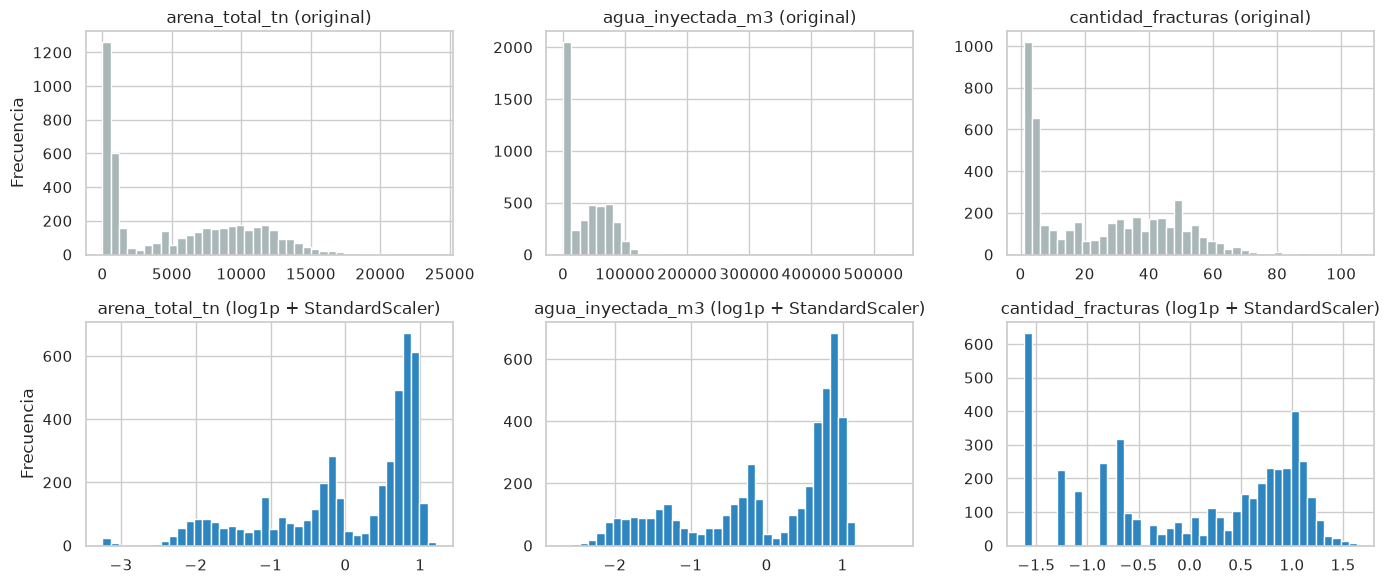

In [ ]:
X_crudo = df_cluster[features].to_numpy(dtype=float)

# Paso 1: log(1 + x) para comprimir valores extremos
X_log = np.log1p(X_crudo)

# Paso 2: estandarización (media 0, desvío 1)
scaler = StandardScaler()
X = scaler.fit_transform(X_log)

# Comparamos visualmente 3 variables antes y después de transformar
vars_muestra = ['arena_total_tn', 'agua_inyectada_m3', 'cantidad_fracturas']
fig, axes = plt.subplots(2, 3, figsize=(14, 6))

for j, col in enumerate(vars_muestra):
    idx_col = features.index(col)
    axes[0, j].hist(X_crudo[:, idx_col], bins=40, color='#AAB7B8', edgecolor='white')
    axes[0, j].set_title(f'{col} (original)')

    axes[1, j].hist(X[:, idx_col], bins=40, color='#2E86C1', edgecolor='white')
    axes[1, j].set_title(f'{col} (log1p + StandardScaler)')

axes[0, 0].set_ylabel('Frecuencia')
axes[1, 0].set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

Al aplicar `log1p + StandardScaler`, dejan de estar todos los datos apretados a la izquierda y ya se empiezan a ver **tres montañas o escalones** en la distribución de la arena, el agua y la cantidad de fracturas.

## Parte 4. Elección de la cantidad de grupos ($K$)

- **Inercia (método del codo):** mide cuán compactos son los grupos por dentro. Como siempre baja al agregar más grupos, buscamos el **"codo"** donde la curva deja de bajar fuerte y se aplana.
- **Coeficiente de Silueta (entre -1 y 1):** mide qué tan bien separados están los grupos entre sí. Cuanto más alto y cercano a 1, mejor definidos están los grupos.

,K,Inercia,Silueta,Tamaños de grupo
0,2,9190.5,0.625,"[1955, 2630]"
1,3,4907.1,0.621,"[915, 1101, 2569]"
2,4,4159.2,0.582,"[557, 598, 864, 2566]"
3,5,3454.0,0.599,"[69, 485, 599, 866, 2566]"
4,6,2966.7,0.556,"[69, 191, 486, 597, 862, 2380]"
5,7,2559.6,0.562,"[68, 190, 311, 314, 466, 856, 2380]"


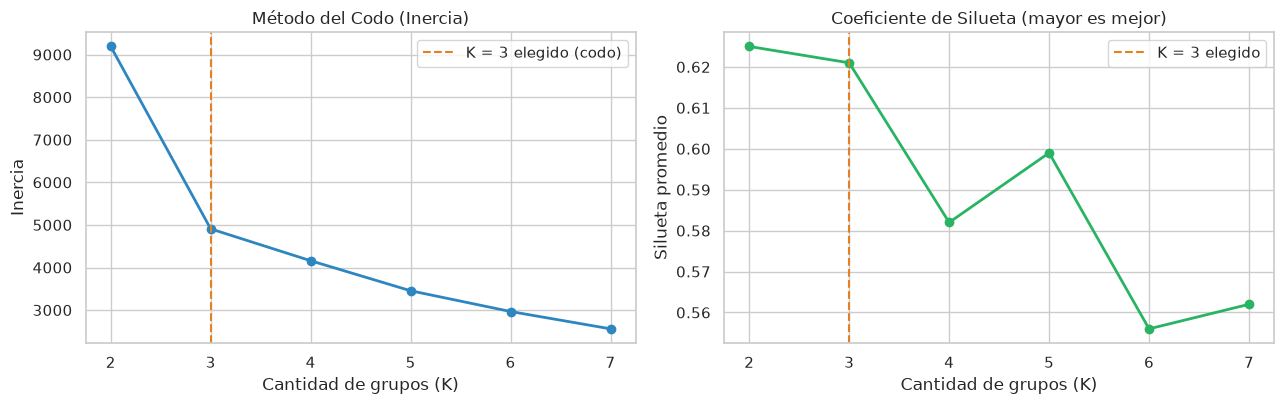

In [ ]:
resultados_k = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    sil = metrics.silhouette_score(X, km.labels_)
    tamanos = sorted(np.bincount(km.labels_).tolist())
    resultados_k.append({
        'K': k,
        'Inercia': round(km.inertia_, 1),
        'Silueta': round(sil, 3),
        'Tamaños de grupo': str(tamanos),
    })

tabla_k = pd.DataFrame(resultados_k)
display(tabla_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].plot(tabla_k['K'], tabla_k['Inercia'], marker='o', lw=2, color='#2E86C1')
axes[0].axvline(3, color='#E67E22', ls='--', label='K = 3 elegido (codo)')
axes[0].set_title('Método del Codo (Inercia)')
axes[0].set_xlabel('Cantidad de grupos (K)')
axes[0].set_ylabel('Inercia')
axes[0].legend()

axes[1].plot(tabla_k['K'], tabla_k['Silueta'], marker='o', lw=2, color='#28B463')
axes[1].axvline(3, color='#E67E22', ls='--', label='K = 3 elegido')
axes[1].set_title('Coeficiente de Silueta (mayor es mejor)')
axes[1].set_xlabel('Cantidad de grupos (K)')
axes[1].set_ylabel('Silueta promedio')
axes[1].legend()

plt.tight_layout()
plt.show()

- **Codo claro en $K = 3$:** al pasar de $K = 2$ a $K = 3$, la inercia cae casi a la mitad (de `9.190,5` a `4.907,1`), y a partir de $K = 4$ baja mucho más lento.
- **Buena silueta y tamaños equilibrados:** en $K = 3$ la silueta es alta (**`0.621`**, prácticamente igual al máximo de `0.625` en $K=2$) y los tres grupos tienen tamaños representativos (`915`, `1.101` y `2.569` registros). En cambio, con $K = 2$ todos los pozos verticales quedan mezclados en una sola bolsa, y a partir de $K = 4$ o $K = 5$ baja la silueta y se empiezan a desprender grupos muy chiquitos.

## Parte 5. Interpretación de los 3 grupos encontrados

Entrenamos el modelo final con **`K = 3`**, ordenamos los números de grupo de menor a mayor consumo de arena (`Grupo 1`, `Grupo 2` y `Grupo 3`) y calculamos la **mediana** de cada variable en sus unidades originales para entender cómo es el pozo típico de cada grupo.

In [ ]:
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)

# Ordenamos las etiquetas (1, 2, 3) de menor a mayor arena promedio para que sea fácil de leer
orden = sorted([0, 1, 2], key=lambda g: df_cluster.loc[kmeans_final.labels_ == g, 'arena_total_tn'].mean())
mapa_grupos = {viejo: nuevo for nuevo, viejo in enumerate(orden, start=1)}
df_cluster['grupo'] = [mapa_grupos[g] for g in kmeans_final.labels_]

# Tabla resumen con la mediana de cada variable en unidades originales
resumen_grupos = df_cluster.groupby('grupo')[features].median().round(1)
resumen_grupos.insert(0, 'Cantidad de registros', df_cluster['grupo'].value_counts().sort_index())
resumen_grupos.insert(1, '% del total', (df_cluster['grupo'].value_counts(normalize=True).sort_index() * 100).round(1))
resumen_grupos.index = ['Grupo 1 (Chicos)', 'Grupo 2 (Medianos)', 'Grupo 3 (Grandes)']

resumen_grupos

,Cantidad de registros,% del total,longitud_rama_horizontal_m,cantidad_fracturas,arena_total_tn,agua_inyectada_m3,presion_maxima_psi,potencia_equipos_fractura_hp
Grupo 1 (Chicos),915,20.0,0.0,1.0,33.0,148.1,3220.0,940.0
Grupo 2 (Medianos),1101,24.0,0.0,5.0,804.2,3518.8,8200.0,18000.0
Grupo 3 (Grandes),2569,56.0,2544.0,41.0,9339.0,58887.0,11688.0,32000.0


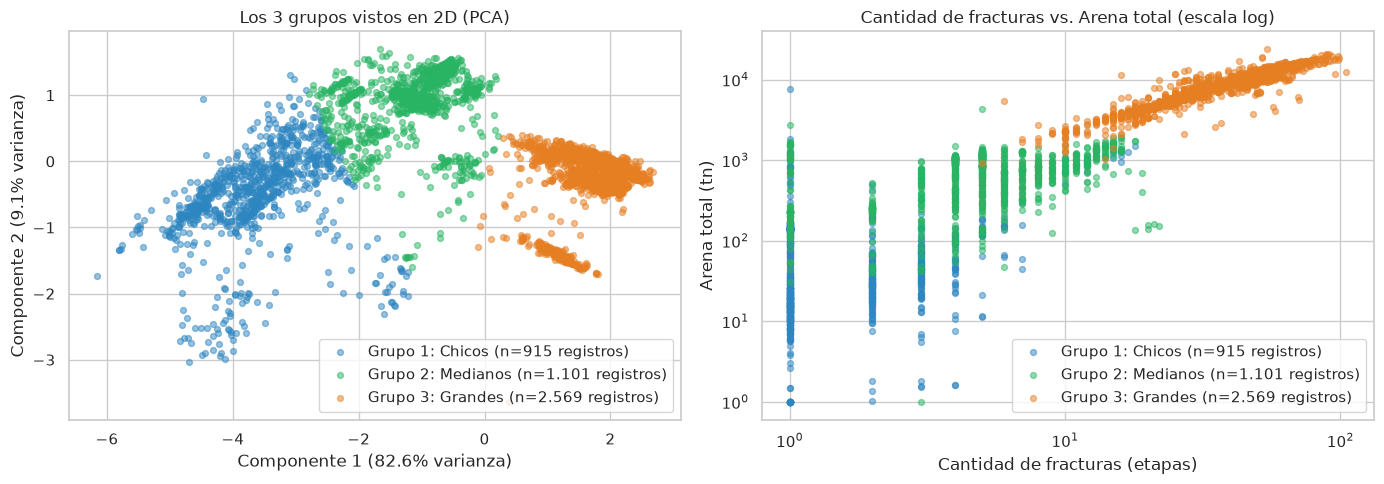

In [ ]:
# Visualizamos los 3 grupos con PCA (reducción de las 6 variables a 2 ejes) y en un gráfico físico
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

nombres = {
    1: 'Grupo 1: Chicos (n=915 registros)',
    2: 'Grupo 2: Medianos (n=1.101 registros)',
    3: 'Grupo 3: Grandes (n=2.569 registros)',
}

for g in [1, 2, 3]:
    mask = df_cluster['grupo'] == g
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=18, alpha=0.5, color=COLORES[g], label=nombres[g])
    axes[1].scatter(df_cluster.loc[mask, 'cantidad_fracturas'],
                    df_cluster.loc[mask, 'arena_total_tn'] + 1,
                    s=18, alpha=0.5, color=COLORES[g], label=nombres[g])

axes[0].set_title('Los 3 grupos vistos en 2D (PCA)')
axes[0].set_xlabel(f'Componente 1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)')
axes[0].set_ylabel(f'Componente 2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)')
axes[0].legend()

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Cantidad de fracturas vs. Arena total (escala log)')
axes[1].set_xlabel('Cantidad de fracturas (etapas)')
axes[1].set_ylabel('Arena total (tn)')
axes[1].legend()

plt.tight_layout()
plt.show()

**Lectura de los 3 perfiles operativos:**

1. **Grupo 1 — Pozos chicos / fractura puntual (`915` registros, 20,0%):**
   - Son pozos verticales (`0 m` de rama horizontal) con **1 sola etapa de fractura**, **33 tn de arena** (lo que carga 1 solo camión), **148 m³ de agua**, baja presión (`3.220 psi`) y equipos chicos (`940 HP`).
2. **Grupo 2 — Pozos medianos / multietapa vertical (`1.101` registros, 24,0%):**
   - Siguen siendo pozos verticales (`0 m` de rama), pero pasan a tener **5 etapas de fractura**, **804 tn de arena** (unos 25 a 30 camiones), **3.519 m³ de agua** y equipos de mucha mayor presión (`8.200 psi`) y potencia (`18.000 HP`).
3. **Grupo 3 — Pozos grandes / horizontales masivos (`2.569` registros, 56,0%):**
   - Son pozos con ramas horizontales largas (**`2.544 m`**), **41 etapas de fractura**, **9.339 tn de arena** (más de 300 camiones por pozo), **58.887 m³ de agua**, **11.688 psi** de presión y **32.000 HP** de potencia.

## Parte 6. Comparación con el tipo de reservorio (validación externa)

Ahora sí cruzamos los 3 grupos que armó K-Means contra las columnas **`subtipo_reservorio`** y **`cuenca`** (que habíamos dejado afuera del modelo) para ver si estos perfiles físicos coinciden con la geología de los pozos, y medimos la coincidencia con el **Índice de Rand Ajustado (`ARI`)** y la **Pureza**.

=== CANTIDAD DE REGISTROS POR GRUPO Y SUBTIPO DE RESERVORIO ===


subtipo_reservorio,no corresponde,shale,tight,All
Grupo 1 (Chicos),593,9,313,915
Grupo 2 (Medianos),60,442,599,1101
Grupo 3 (Grandes),2,2562,5,2569
Total,655,3013,917,4585



=== PORCENTAJE DENTRO DE CADA GRUPO (%) ===


subtipo_reservorio,no corresponde,shale,tight
Grupo 1 (Chicos),64.8,1.0,34.2
Grupo 2 (Medianos),5.4,40.1,54.4
Grupo 3 (Grandes),0.1,99.7,0.2



Pureza respecto a subtipo_reservorio: 0.819
Adjusted Rand Index (ARI):            0.632


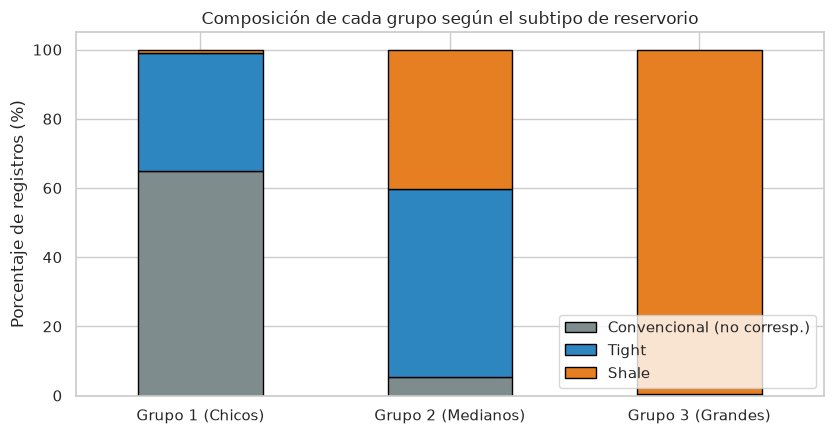

In [ ]:
tabla_cruzada = pd.crosstab(df_cluster['grupo'], df_cluster['subtipo_reservorio'], margins=True)
tabla_cruzada.index = ['Grupo 1 (Chicos)', 'Grupo 2 (Medianos)', 'Grupo 3 (Grandes)', 'Total']
print('=== CANTIDAD DE REGISTROS POR GRUPO Y SUBTIPO DE RESERVORIO ===')
display(tabla_cruzada)

tabla_pct = (pd.crosstab(df_cluster['grupo'], df_cluster['subtipo_reservorio'], normalize='index') * 100).round(1)
tabla_pct.index = ['Grupo 1 (Chicos)', 'Grupo 2 (Medianos)', 'Grupo 3 (Grandes)']
print('\n=== PORCENTAJE DENTRO DE CADA GRUPO (%) ===')
display(tabla_pct)

# Métricas externas vistas en clase
pureza = pd.crosstab(df_cluster['grupo'], df_cluster['subtipo_reservorio']).max(axis=1).sum() / len(df_cluster)
ari = metrics.adjusted_rand_score(df_cluster['subtipo_reservorio'], df_cluster['grupo'])
print(f'\nPureza respecto a subtipo_reservorio: {pureza:.3f}')
print(f'Adjusted Rand Index (ARI):            {ari:.3f}')

# Gráfico de composición de cada grupo
ax = tabla_pct[['no corresponde', 'tight', 'shale']].rename(
    columns={'no corresponde': 'Convencional (no corresp.)', 'tight': 'Tight', 'shale': 'Shale'}
).plot(kind='bar', stacked=True, figsize=(8.5, 4.5), color=['#7F8C8D', '#2E86C1', '#E67E22'], edgecolor='black')

ax.set_title('Composición de cada grupo según el subtipo de reservorio')
ax.set_ylabel('Porcentaje de registros (%)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**¿Qué nos muestra este cruce?**

- **El Grupo 3 (Grandes) es 99,7% Shale:** sin haber visto la etiqueta geológica, el modelo separó casi a la perfección los pozos horizontales no convencionales de Vaca Muerta (`2.562` de `2.569` registros).
- **El Grupo 1 (Chicos) concentra a los Convencionales (`64,8%`)** y a los pozos *Tight* más chicos (`34,2%`), que llevan muy poca arena.
- **El Grupo 2 (Medianos) reúne a los pozos Tight de mayor escala (`54,4%`) junto con `442` registros Shale de pozos verticales (`40,1%`):** esos pozos *shale* del Grupo 2 son los primeros pozos verticales que se hicieron en Vaca Muerta (alrededor de 2012–2016) antes de que se usaran ramas horizontales largas. Desde el punto de vista de la logística de arena, un pozo vertical de Vaca Muerta consumía unas 800 tn (como un pozo *tight* mediano), muy lejos de las 9.300 tn de los pozos horizontales actuales.

=== CANTIDAD DE REGISTROS POR GRUPO Y CUENCA ===


cuenca,austral,golfo san jorge,neuquina,All
Grupo 1 (Chicos),202,282,431,915
Grupo 2 (Medianos),11,26,1064,1101
Grupo 3 (Grandes),1,0,2568,2569
Total,214,308,4063,4585



=== EN QUÉ GRUPO CAEN LOS REGISTROS DE CADA CUENCA (%) ===


cuenca,austral,golfo san jorge,neuquina
Grupo 1 (Chicos),94.4,91.6,10.6
Grupo 2 (Medianos),5.1,8.4,26.2
Grupo 3 (Grandes),0.5,0.0,63.2



=== REGISTROS TIGHT DEL GRUPO 1 POR CUENCA ===
cuenca
austral            195
neuquina           116
golfo san jorge      2


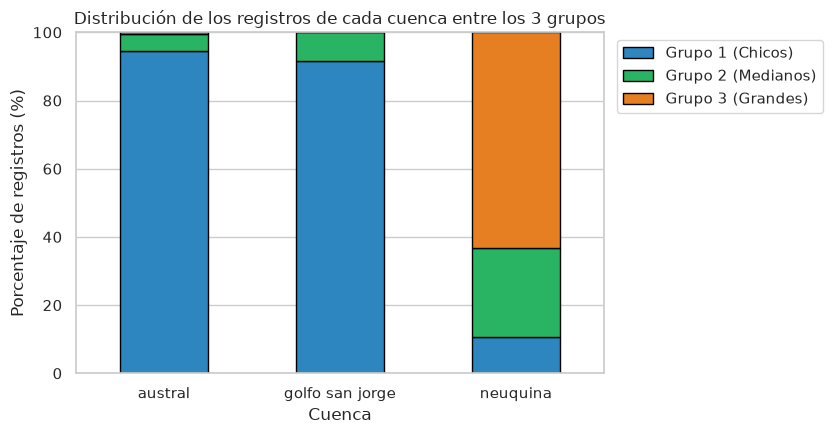

In [ ]:
tabla_cuenca = pd.crosstab(df_cluster['grupo'], df_cluster['cuenca'], margins=True)
tabla_cuenca.index = ['Grupo 1 (Chicos)', 'Grupo 2 (Medianos)', 'Grupo 3 (Grandes)', 'Total']
print('=== CANTIDAD DE REGISTROS POR GRUPO Y CUENCA ===')
display(tabla_cuenca)

# Distribución de cada cuenca entre los 3 grupos (cada columna suma 100%)
tabla_cuenca_pct = (pd.crosstab(df_cluster['grupo'], df_cluster['cuenca'], normalize='columns') * 100).round(1)
tabla_cuenca_pct.index = ['Grupo 1 (Chicos)', 'Grupo 2 (Medianos)', 'Grupo 3 (Grandes)']
print('\n=== EN QUÉ GRUPO CAEN LOS REGISTROS DE CADA CUENCA (%) ===')
display(tabla_cuenca_pct)

# ¿De qué cuenca son los pozos tight chicos del Grupo 1?
tight_g1 = df_cluster.loc[(df_cluster['grupo'] == 1) & (df_cluster['subtipo_reservorio'] == 'tight'), 'cuenca'].value_counts()
print('\n=== REGISTROS TIGHT DEL GRUPO 1 POR CUENCA ===')
print(tight_g1.to_string())

ax = tabla_cuenca_pct.T[['Grupo 1 (Chicos)', 'Grupo 2 (Medianos)', 'Grupo 3 (Grandes)']].plot(
    kind='bar', stacked=True, figsize=(8.5, 4.5), color=[COLORES[1], COLORES[2], COLORES[3]], edgecolor='black'
)
ax.set_title('Distribución de los registros de cada cuenca entre los 3 grupos')
ax.set_xlabel('Cuenca')
ax.set_ylabel('Porcentaje de registros (%)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()


**¿Qué nos muestra el cruce por cuenca?**

- **Las cuencas Austral y Golfo San Jorge caen casi enteras en el Grupo 1 (Chicos):** el `94,4%` de los registros de Austral (`202` de `214`) y el `91,6%` de los de Golfo San Jorge (`282` de `308`). Ninguna de las dos aporta registros al Grupo 3, salvo uno solo de Austral.
- **La cuenca Neuquina es la única que aparece en los tres perfiles:** el `63,2%` de sus registros está en el Grupo 3 (Grandes), el `26,2%` en el Grupo 2 y el `10,6%` en el Grupo 1. Prácticamente todo el Grupo 3 (`2.568` de `2.569` registros) es neuquino, lo que coincide con el desarrollo de Vaca Muerta.
- **Los pozos *Tight* chicos del Grupo 1 son sobre todo de la cuenca Austral:** de los `313` registros *tight* del Grupo 1, `195` son de Austral y `116` de Neuquina. En cambio, los *tight* de mayor escala (Grupo 2) son casi todos neuquinos.
- **Lectura para la logística:** el perfil de fractura sigue también a la geografía. Las operaciones del sur (Golfo San Jorge y Austral) requieren equipos y volúmenes de arena chicos, mientras que la demanda masiva de arena, agua y potencia se concentra en la cuenca Neuquina.
